In [13]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt

In [14]:

print("-- First 150k --\n")
df_kaggle = pd.read_csv("../dataset/raw/Kaggle/winemag-data_first150k.csv")
print(df_kaggle.shape)
print(df_kaggle.columns)


print("\n-- v2 130k --\n")
df_kaggle_v2 = pd.read_csv("../dataset/raw/Kaggle/winemag-data-130k-v2.csv")  # extra 'taster_name','taster_twitter_handle','title'
print(df_kaggle_v2.shape)
print(df_kaggle_v2.columns)

common = df_kaggle.columns.intersection(df_kaggle_v2.columns) #give you common columns between df_kaggle and df_kaggle_v2
print(list(common))

df = pd.concat([df_kaggle[common],df_kaggle_v2[common]], ignore_index=True) #merge
print(df.info())
print(df.describe())

-- First 150k --

(150930, 11)
Index(['Unnamed: 0', 'country', 'description', 'designation', 'points',
       'price', 'province', 'region_1', 'region_2', 'variety', 'winery'],
      dtype='str')

-- v2 130k --

(129971, 14)
Index(['Unnamed: 0', 'country', 'description', 'designation', 'points',
       'price', 'province', 'region_1', 'region_2', 'taster_name',
       'taster_twitter_handle', 'title', 'variety', 'winery'],
      dtype='str')
['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']
<class 'pandas.DataFrame'>
RangeIndex: 280901 entries, 0 to 280900
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Unnamed: 0   280901 non-null  int64  
 1   country      280833 non-null  str    
 2   description  280901 non-null  str    
 3   designation  197701 non-null  str    
 4   points       280901 non-null  int64  
 5   price        258

In [15]:
#info about data
print(df.shape)

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "full": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
summary

(280901, 11)


,dtype,full,missing,missing_%,unique
Unnamed: 0,int64,280901,0,0.00,150930
country,str,280833,68,0.02,50
description,str,280901,0,0.00,169430
designation,str,197701,83200,29.62,47239
points,int64,280901,0,0.00,21
price,float64,258210,22691,8.08,415
province,str,280833,68,0.02,490
region_1,str,234594,46307,16.49,1332
region_2,str,111464,169437,60.32,18
variety,str,280900,1,0.00,756


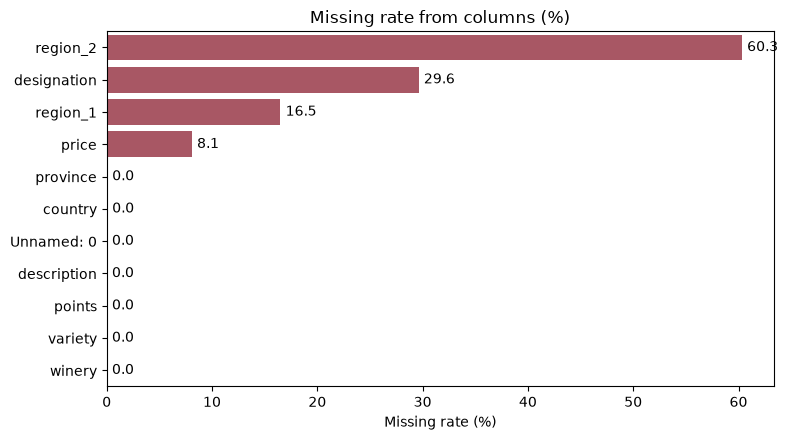

In [17]:
# visualazing missing value

missing = summary.sort_values("missing_%", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=missing["missing_%"], y=missing.index, ax=ax, color="#b5495b")
ax.set_title("Missing rate from columns (%)")
ax.set_xlabel("Missing rate (%)"); ax.set_ylabel("")
for i, v in enumerate(missing["missing_%"]):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center")
plt.tight_layout(); plt.show()

In [ ]:
print(df.columns)
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.duplicated().sum())



Index(['Unnamed: 0', 'country', 'description', 'designation', 'points',
       'price', 'province', 'region_1', 'region_2', 'variety', 'winery'],
      dtype='str')
1
0


In [ ]:
columns = [
    "Class",
    "Alcohol",
 	"Malic acid",
 	"Ash",
	"Alcalinity of ash",
 	"Magnesium",
	"Total phenols",
 	"Flavanoids",
 	"Nonflavanoid phenols",
 	"Proanthocyanins",
	"Color intensity",
 	"Hue",
 	"OD280/OD315 of diluted wines",
 	"Proline" 
]

df_UCI = pd.read_csv("../dataset/raw/UCI/wine.data",
    header=None,
    names = columns
)

print(df_UCI.shape)
print(df_UCI.columns)
print(df_UCI.head())

(178, 14)
Index(['Class', 'Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash',
       'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols',
       'Proanthocyanins', 'Color intensity', 'Hue',
       'OD280/OD315 of diluted wines', 'Proline'],
      dtype='str')
   Class  Alcohol  Malic acid   Ash  Alcalinity of ash  Magnesium  \
0      1    14.23        1.71  2.43               15.6        127   
1      1    13.20        1.78  2.14               11.2        100   
2      1    13.16        2.36  2.67               18.6        101   
3      1    14.37        1.95  2.50               16.8        113   
4      1    13.24        2.59  2.87               21.0        118   

   Total phenols  Flavanoids  Nonflavanoid phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3